<a href="https://colab.research.google.com/github/govardhansnair/Black-Scholes_Options_Pricing_Model/blob/main/02_Black_Scholes_Project_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter current stock price: 100
Enter strike price: 105
Enter time to expiry in years: 1
Enter risk-free interest rate (%): 5
Enter annual volatility (%): 20
Enter dividend yield (%) [enter 0 if none]: 0
 RESULTS

--- d1 AND d2 ---
d1: 0.106
d2: -0.094
N(d1): 0.5422
N(d2): 0.4626

--- OPTION PRICES ---
CALL PRICE: 8.0214
PUT PRICE: 7.9004

--- OPTION VALUE COMPONENTS ---
Call Intrinsic Value: 0
Call Time Value: 8.0214
Put Intrinsic Value: 5.0
Put Time Value: 2.9004
Moneyness: OTM for Call, ITM for Put

--- GREEKS ---
Call Delta: 0.5422
Put Delta: -0.4578
Gamma: 0.0198
Call Theta per year: -6.6509
Put Theta per year: -1.2832
Vega: 39.6705
Vega per 1% volatility change: 0.3967
Call Rho: 46.2015
Put Rho: -45.7218
Call Rho per 1% rate change: 0.462
Put Rho per 1% rate change: -0.4572

--- BINARY OPTIONS ---
Binary Call: 0.44
Binary Put: 0.5112

--- PUT-CALL PARITY ---
Call - Put: 0.12091
Theoretical parity: 0.12091
Difference: 0.0


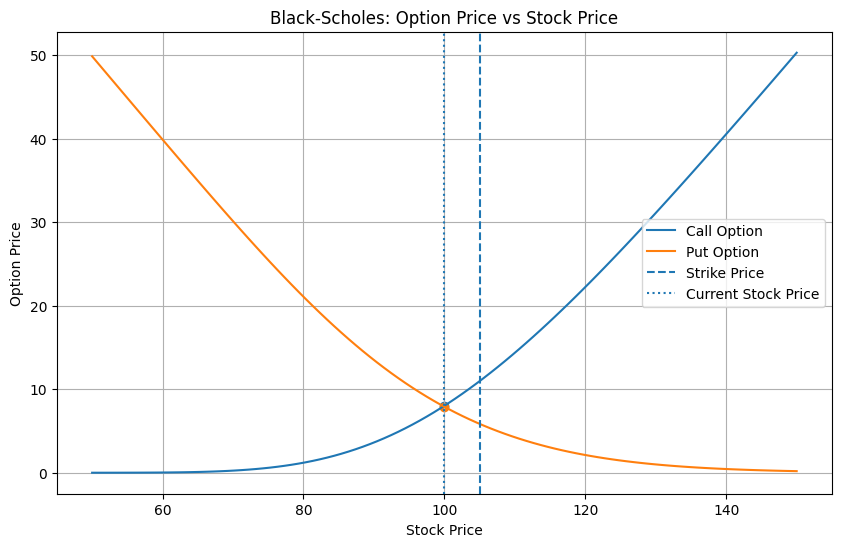

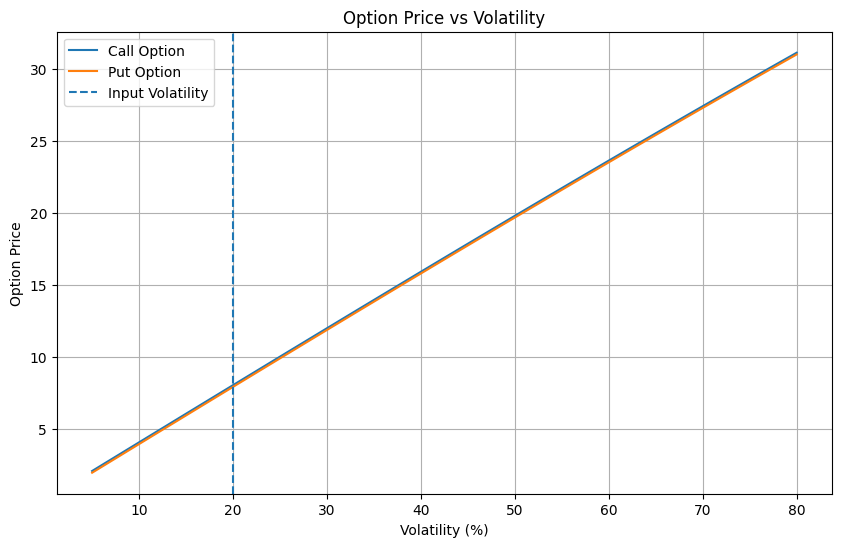

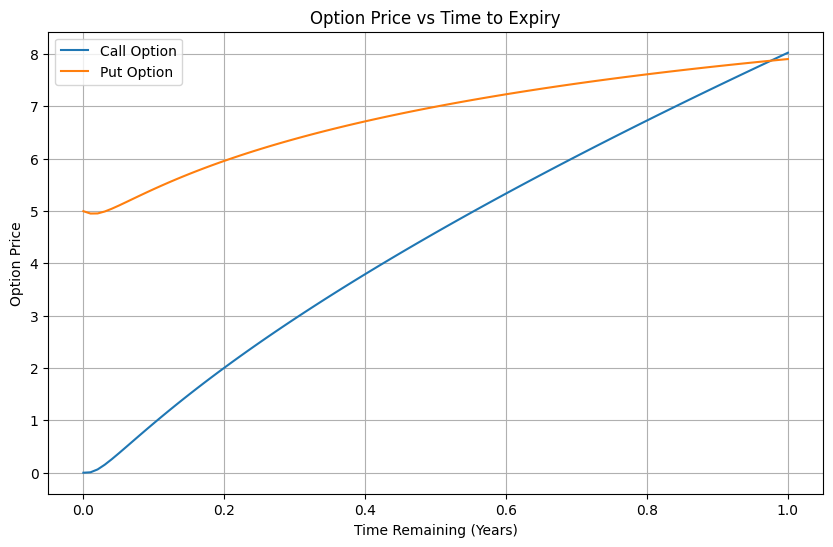

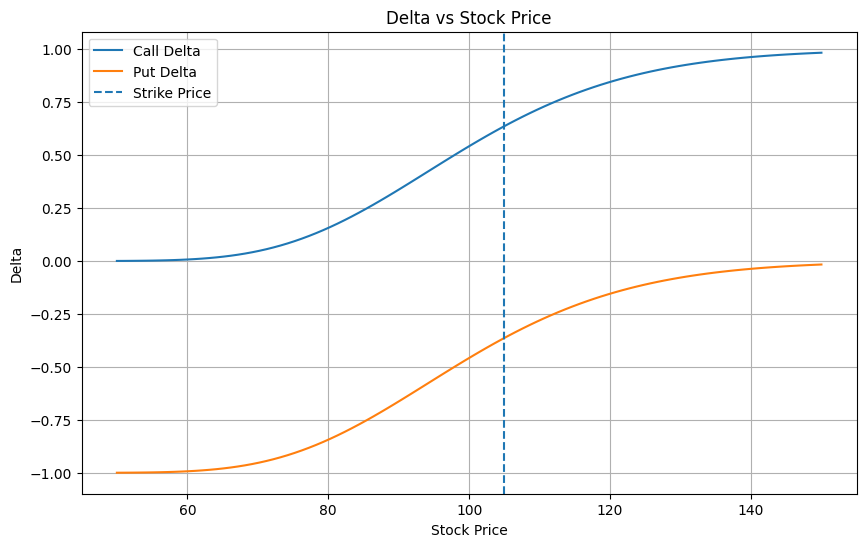

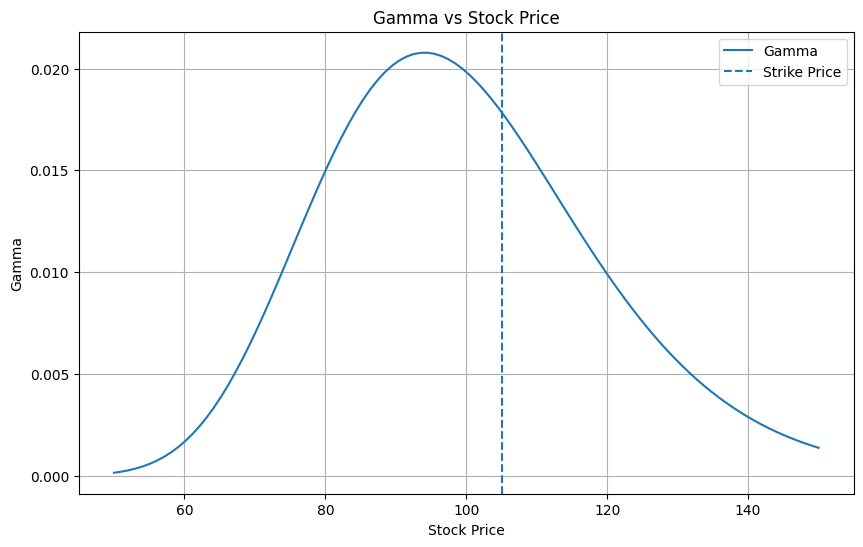

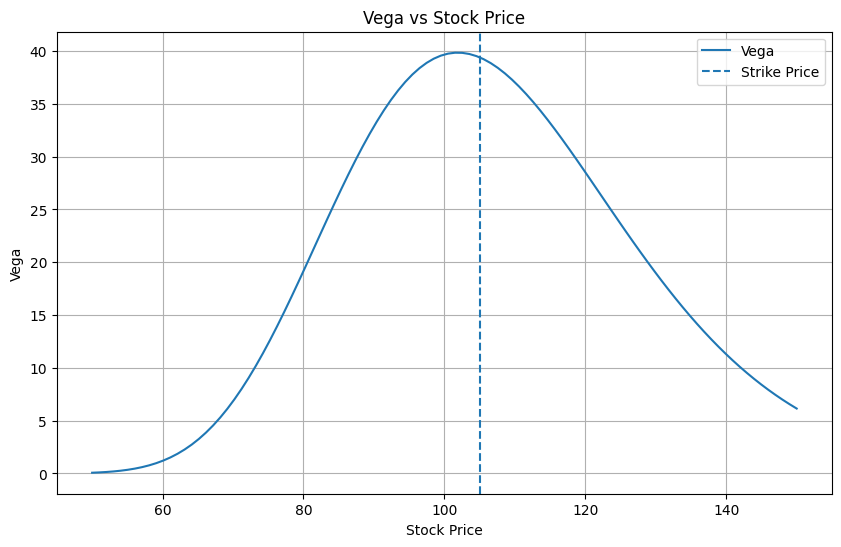

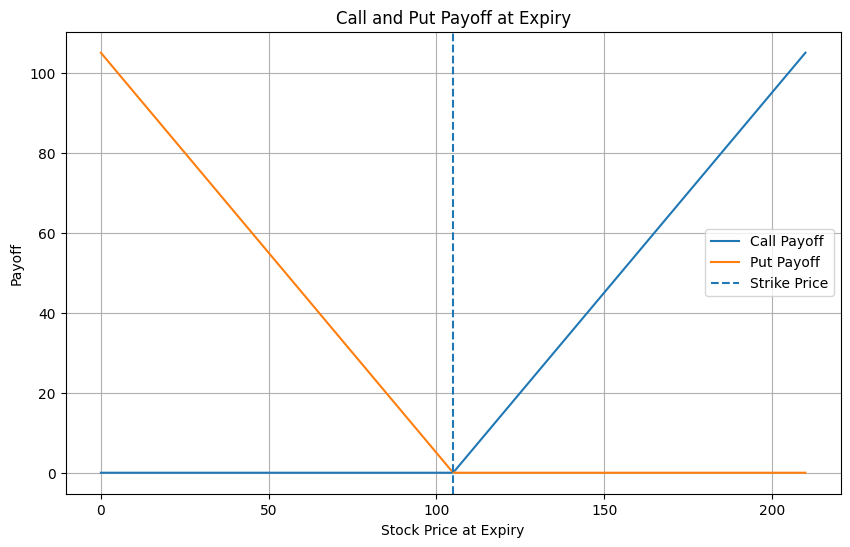

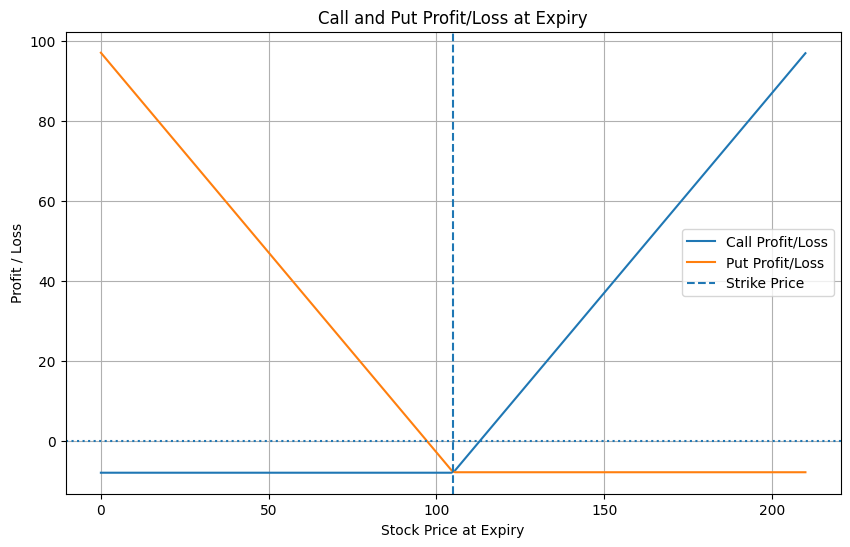

BLACK-SCHOLES MODEL COMPLETED


In [ ]:
# BLACK-SCHOLES OPTIONS PRICING MODEL

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


# INPUTS
S = float(input("Enter current stock price: "))
E = float(input("Enter strike price: "))
T = float(input("Enter time to expiry in years: "))
r = float(input("Enter risk-free interest rate (%): "))
sigma = float(input("Enter annual volatility (%): "))
q = float(input("Enter dividend yield (%) [enter 0 if none]: "))


# CONVERT PERCENTAGES INTO DECIMALS

r = r / 100
sigma = sigma / 100
q = q / 100


# CHECK INPUTS

if S <= 0 or E <= 0 or T <= 0 or sigma <= 0:
  raise ValueError("Stock price, strike price, time and volatility must be positive.")


# CALCULATE d1 AND d2

d1=(np.log(S/E)+(r-q+0.5*sigma**2)*T)/(sigma*np.sqrt(T))
d2=d1-sigma*np.sqrt(T)


# CALCULATE NORMAL DISTRIBUTION VALUES

N_d1=norm.cdf(d1)
N_d2=norm.cdf(d2)

N_minus_d1=norm.cdf(-d1)
N_minus_d2=norm.cdf(-d2)

# Normal probability density function

phi_d1=norm.pdf(d1)


# CALCULATE CALL AND PUT PRICES

call_price=(S*np.exp(-q*T)*N_d1-E*np.exp(-r*T)*N_d2)

put_price=(E*np.exp(-r*T)*N_minus_d2-S*np.exp(-q*T)*N_minus_d1)


# GREEKS

# DELTA
call_delta=np.exp(-q*T)*N_d1
put_delta=np.exp(-q*T)*(N_d1-1)

# GAMMA
gamma=np.exp(-q*T)*phi_d1/(S*sigma*np.sqrt(T))

# THETA
common_theta=(-S*np.exp(-q*T)*phi_d1*sigma/(2*np.sqrt(T)))
call_theta=(common_theta-r*E*np.exp(-r*T)*N_d2+q*S*np.exp(-q*T)*N_d1)
put_theta=(common_theta+r*E*np.exp(-r*T)*N_minus_d2-q*S*np.exp(-q*T)*N_minus_d1)


# VEGA
vega=(S*np.exp(-q*T)*phi_d1*np.sqrt(T))
vega_per_point=vega/100


# RHO

call_rho=E*T*np.exp(-r*T)*N_d2
put_rho=-E*T*np.exp(-r*T)*N_minus_d2

call_rho_per_point=call_rho/100
put_rho_per_point=put_rho/100

# Binary Options

binary_call=np.exp(-r*T)*N_d2
binary_put=np.exp(-r*T)*N_minus_d2


# Intrinsic Value
call_intrinsic=max(S-E,0)
put_intrinsic=max(E-S,0)



# Time Value
call_time_value=call_price-call_intrinsic
put_time_value=put_price-put_intrinsic


# IDENTIFY MONEYNESS

if S > E:
  moneyness = "ITM for Call, OTM for Put"

elif S < E:
  moneyness = "OTM for Call, ITM for Put"

else:
  moneyness = "ATM for both Call and Put"


# STEP 13: CHECK PUT-CALL PARITY

parity_left=call_price-put_price

parity_right=(S*np.exp(-q*T)-E*np.exp(-r*T))
parity_difference=parity_left-parity_right


# RESULTS


print(" RESULTS")

print("\n--- d1 AND d2 ---")

print("d1:", round(d1, 4))
print("d2:", round(d2, 4))

print("N(d1):", round(N_d1, 4))
print("N(d2):", round(N_d2, 4))


print("\n--- OPTION PRICES ---")

print("CALL PRICE:", round(call_price, 4))
print("PUT PRICE:", round(put_price, 4))


print("\n--- OPTION VALUE COMPONENTS ---")

print("Call Intrinsic Value:", round(call_intrinsic, 4))
print("Call Time Value:", round(call_time_value, 4))

print("Put Intrinsic Value:", round(put_intrinsic, 4))
print("Put Time Value:", round(put_time_value, 4))

print("Moneyness:", moneyness)


print("\n--- GREEKS ---")

print("Call Delta:", round(call_delta, 4))
print("Put Delta:", round(put_delta, 4))

print("Gamma:", round(gamma, 4))

print("Call Theta per year:", round(call_theta, 4))
print("Put Theta per year:", round(put_theta, 4))

print("Vega:", round(vega, 4))
print("Vega per 1% volatility change:", round(vega_per_point, 4))

print("Call Rho:", round(call_rho, 4))
print("Put Rho:", round(put_rho, 4))

print("Call Rho per 1% rate change:", round(call_rho_per_point, 4))
print("Put Rho per 1% rate change:", round(put_rho_per_point, 4))


print("\n--- BINARY OPTIONS ---")

print("Binary Call:", round(binary_call, 4))
print("Binary Put:", round(binary_put, 4))


print("\n--- PUT-CALL PARITY ---")

print("Call - Put:", round(parity_left, 6))
print("Theoretical parity:", round(parity_right, 6))

print("Difference:", round(parity_difference, 10))



# GRAPH 1: OPTION PRICE AGAINST STOCK PRICE


stock_prices = np.linspace(S * 0.5, S * 1.5, 100)

d1_graph=(np.log(stock_prices / E)+(r-q+0.5*sigma**2)*T)/(sigma*np.sqrt(T))

d2_graph=d1_graph-sigma*np.sqrt(T)


call_graph=(stock_prices*np.exp(-q*T)*norm.cdf(d1_graph)-E*np.exp(-r*T)*
            norm.cdf(d2_graph))

put_graph = (E*np.exp(-r*T)*norm.cdf(-d2_graph)-stock_prices*np.exp(-q*T)*
             norm.cdf(-d1_graph))


plt.figure(figsize=(10, 6))

plt.plot(stock_prices, call_graph, label="Call Option")
plt.plot(stock_prices, put_graph, label="Put Option")

plt.axvline(E, linestyle="--", label="Strike Price")
plt.axvline(S, linestyle=":", label="Current Stock Price")

plt.scatter(S, call_price)
plt.scatter(S, put_price)

plt.xlabel("Stock Price")
plt.ylabel("Option Price")

plt.title("Black-Scholes: Option Price vs Stock Price")

plt.legend()
plt.grid(True)

plt.show()


# GRAPH 2: OPTION PRICE AGAINST VOLATILITY


volatility_range=np.linspace(0.05, max(0.80, 2*sigma), 100)

d1_vol =(np.log(S/E)+(r-q + 0.5 * volatility_range**2)*T)/(volatility_range*np.sqrt(T))

d2_vol =d1_vol-volatility_range*np.sqrt(T)


call_vol = (S *np.exp(-q*T)*norm.cdf(d1_vol)- E*np.exp(-r*T)*norm.cdf(d2_vol))

put_vol =(E*np.exp(-r*T)*norm.cdf(-d2_vol)-S* np.exp(-q*T)*norm.cdf(-d1_vol))


plt.figure(figsize=(10,6))

plt.plot(volatility_range * 100, call_vol, label="Call Option")
plt.plot(volatility_range * 100, put_vol, label="Put Option")

plt.axvline(sigma*100, linestyle="--", label="Input Volatility")

plt.xlabel("Volatility (%)")
plt.ylabel("Option Price")

plt.title("Option Price vs Volatility")

plt.legend()
plt.grid(True)

plt.show()


# GRAPH 3: OPTION PRICE AGAINST TIME TO EXPIRY

time_range = np.linspace(max(T/1000, 0.0001), T, 100)

d1_time=(np.log(S/E)+(r-q+0.5*sigma**2)*time_range)/(sigma*np.sqrt(time_range))

d2_time=d1_time-sigma*np.sqrt(time_range)


call_time=(S*np.exp(-q*time_range)*norm.cdf(d1_time)-E*np.exp(-r*time_range)*
           norm.cdf(d2_time))

put_time=(E*np.exp(-r*time_range)*norm.cdf(-d2_time)-S*np.exp(-q*time_range)
* norm.cdf(-d1_time))


plt.figure(figsize=(10, 6))

plt.plot(time_range, call_time, label="Call Option")
plt.plot(time_range, put_time, label="Put Option")

plt.xlabel("Time Remaining (Years)")
plt.ylabel("Option Price")

plt.title("Option Price vs Time to Expiry")

plt.legend()
plt.grid(True)

plt.show()


# GRAPH 4: DELTA AGAINST STOCK PRICE

delta_call_graph = np.exp(-q*T) * norm.cdf(d1_graph)

delta_put_graph = (np.exp(-q*T)*(norm.cdf(d1_graph)-1))


plt.figure(figsize=(10, 6))

plt.plot(stock_prices, delta_call_graph, label="Call Delta")
plt.plot(stock_prices, delta_put_graph, label="Put Delta")

plt.axvline(E, linestyle="--", label="Strike Price")

plt.xlabel("Stock Price")
plt.ylabel("Delta")

plt.title("Delta vs Stock Price")

plt.legend()
plt.grid(True)

plt.show()



# GRAPH 5: GAMMA AGAINST STOCK PRICE

gamma_graph = (np.exp(-q*T)*norm.pdf(d1_graph)/(stock_prices*sigma*np.sqrt(T)))


plt.figure(figsize=(10, 6))

plt.plot(stock_prices, gamma_graph, label="Gamma")

plt.axvline(E, linestyle="--", label="Strike Price")

plt.xlabel("Stock Price")
plt.ylabel("Gamma")

plt.title("Gamma vs Stock Price")

plt.legend()
plt.grid(True)

plt.show()


# GRAPH 6: VEGA AGAINST STOCK PRICE

vega_graph=(stock_prices*np.exp(-q*T)*norm.pdf(d1_graph)*np.sqrt(T))

plt.figure(figsize=(10, 6))

plt.plot(stock_prices, vega_graph, label="Vega")

plt.axvline(E, linestyle="--", label="Strike Price")

plt.xlabel("Stock Price")
plt.ylabel("Vega")

plt.title("Vega vs Stock Price")

plt.legend()
plt.grid(True)

plt.show()


# GRAPH 7: OPTION PAYOFF AT EXPIRY

expiry_prices=np.linspace(0, 2*E, 200)

call_payoff=np.maximum(expiry_prices-E,0)

put_payoff=np.maximum(E-expiry_prices,0)


plt.figure(figsize=(10, 6))

plt.plot(expiry_prices, call_payoff, label="Call Payoff")
plt.plot(expiry_prices, put_payoff, label="Put Payoff")

plt.axvline(E, linestyle="--", label="Strike Price")

plt.xlabel("Stock Price at Expiry")
plt.ylabel("Payoff")

plt.title("Call and Put Payoff at Expiry")

plt.legend()
plt.grid(True)

plt.show()



# GRAPH 8: OPTION PROFIT AND LOSS


call_profit=call_payoff-call_price

put_profit=put_payoff-put_price


plt.figure(figsize=(10, 6))

plt.plot(expiry_prices, call_profit, label="Call Profit/Loss")
plt.plot(expiry_prices, put_profit, label="Put Profit/Loss")

plt.axhline(0, linestyle=":")
plt.axvline(E, linestyle="--", label="Strike Price")

plt.xlabel("Stock Price at Expiry")
plt.ylabel("Profit / Loss")

plt.title("Call and Put Profit/Loss at Expiry")

plt.legend()
plt.grid(True)

plt.show()



print("BLACK-SCHOLES MODEL COMPLETED")
